# Walkthrough: two-stage FX margin forecaster

1. **Market data:** real FX rates from FRED.
2. **The business layer:** how a markup and a settlement delay turn into a daily margin (simulated).
3. **Stage 1:** a trend of past margins.
4. **Stage 2 and the results:** what machine learning adds, and the floor nobody can beat.
5. **Margin at risk:** a calibrated 5% band.
6. **What drives the correction:** SHAP.

All logic lives in `src/`. For the full method with formulas, see the [methodology notebook](methodology.ipynb). Volumes come from [Project 2](https://github.com/marlondocouto2/cash-flow-forecaster).

In [1]:
import os, sys, warnings
os.environ.setdefault('OMP_NUM_THREADS', '1')
warnings.filterwarnings('ignore')
sys.path.insert(0, '../src')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fx_margin.config import CONFIG
from fx_margin.data import load_market
from fx_margin.business import simulate_business
from fx_margin.features import build_dataset, FEATURES
from fx_margin.models import load_params, make_model
from fx_margin.evaluate import walk_forward, accuracy_table, risk_table
from fx_margin import plots
from fx_margin.plots import INK, INK_2, GRID, MODEL_COLORS

## 1. Market data
Daily FX rates from FRED (foreign currency per U.S. dollar), indexed to 100 at the start. Higher means the currency weakened against the dollar.

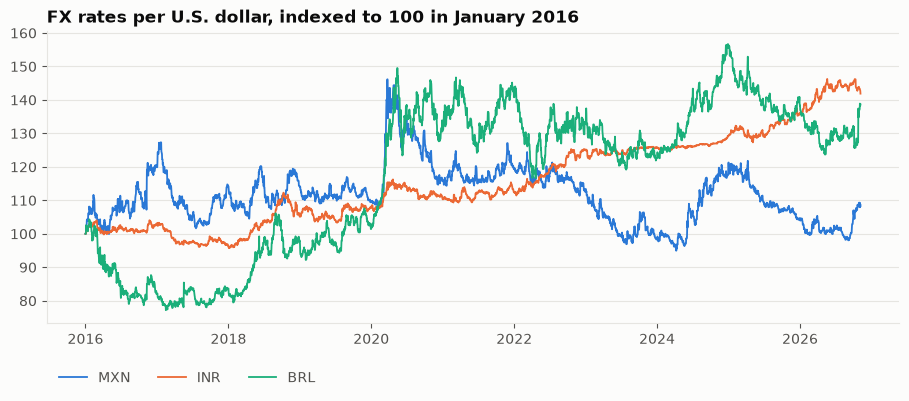

In [2]:
market = load_market()
fx = market[['DEXMXUS', 'DEXINUS', 'DEXBZUS']].rename(columns={'DEXMXUS': 'MXN', 'DEXINUS': 'INR', 'DEXBZUS': 'BRL'})
fig, ax = plt.subplots(figsize=(11, 3.8))
for (name, s), c in zip(fx.items(), ['#2a78d6', '#eb6834', '#1baf7a']):
    ax.plot(s.index, s / s.iloc[0] * 100, color=c, lw=1.3, label=name)
ax.set_title('FX rates per U.S. dollar, indexed to 100 in January 2016')
ax.legend(ncols=3, loc='upper left', bbox_to_anchor=(0, -0.12));

## 2. The business layer (simulated)
The customer gets yesterday's market rate minus a markup; the business buys the currency 1–2 business days later. Realized margin = markup + the currency's move until settlement. Below: Mexico in 2025, markup versus realized margin.

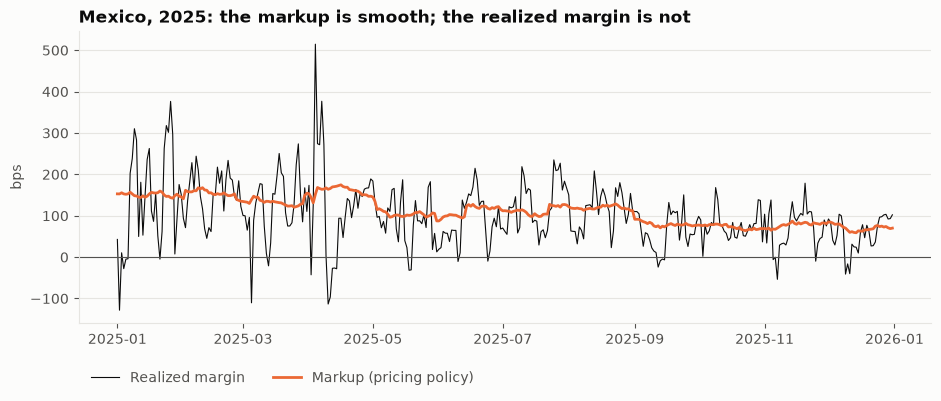

In [3]:
business = simulate_business(market)
mx = business[(business.corridor == 'MX') & business.date.between('2025-01-01', '2025-12-31')].set_index('date')
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(mx.index, mx.margin_rate * 1e4, color=INK, lw=0.8, label='Realized margin')
ax.plot(mx.index, mx.markup * 1e4, color='#eb6834', lw=2, label='Markup (pricing policy)')
ax.axhline(0, color=INK_2, lw=0.8)
ax.set_ylabel('bps'); ax.set_title('Mexico, 2025: the markup is smooth; the realized margin is not')
ax.legend(ncols=2, loc='upper left', bbox_to_anchor=(0, -0.12));

In [4]:
summary = business.groupby('currency').agg(
    avg_markup_bps=('markup', lambda x: x.mean() * 1e4), avg_margin_bps=('margin_rate', lambda x: x.mean() * 1e4),
    days_with_negative_margin=('margin_rate', lambda x: f'{(x < 0).mean():.1%}'),
    avg_daily_margin_usd=('margin_usd', lambda x: f'${x.mean() / 1e3:,.0f}k'))
summary.round(0)

,avg_markup_bps,avg_margin_bps,days_with_negative_margin,avg_daily_margin_usd
currency,,,,
BRL,155.0,157.0,8.7%,$430k
INR,109.0,113.0,1.3%,$551k
MXN,118.0,120.0,9.7%,$741k


## 3. Stage 1: a trend of past margins
The EWMA trend only uses margins at least 4 days old, which have certainly settled. It follows the markup's level, with a lag.

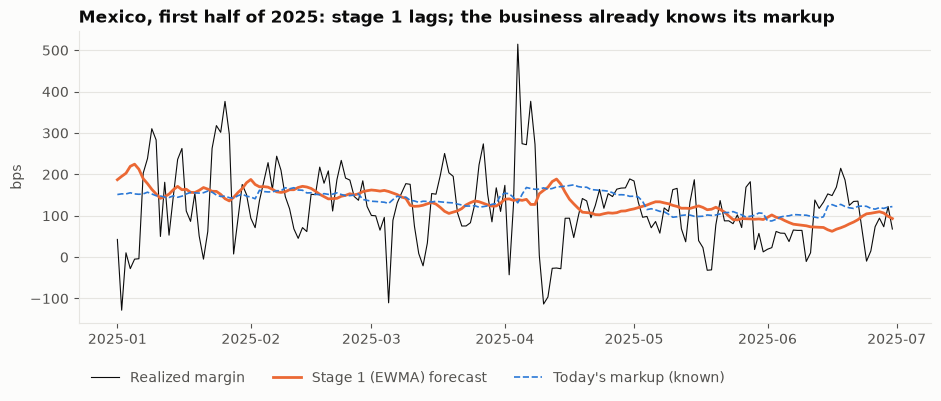

In [5]:
data = build_dataset(business, market)
d = data[(data.corridor == 'MX') & (data.horizon == 1) & data.target.between('2025-01-01', '2025-06-30')].set_index('target')
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(d.index, d.margin_rate * 1e4, color=INK, lw=0.8, label='Realized margin')
ax.plot(d.index, d.s1_ewma * 1e4, color='#eb6834', lw=2, label='Stage 1 (EWMA) forecast')
ax.plot(d.index, d.markup_now * 1e4, color='#2a78d6', lw=1.2, ls='--', label="Today's markup (known)")
ax.set_ylabel('bps'); ax.set_title('Mexico, first half of 2025: stage 1 lags; the business already knows its markup')
ax.legend(ncols=3, loc='upper left', bbox_to_anchor=(0, -0.12));

## 4. Stage 2 and the results
A walk-forward over the last two years: stage 2 refit every 30 days on settled data only. About 20 seconds.

In [6]:
bt = walk_forward(data, business, load_params())
acc = accuracy_table(bt)
acc[acc.horizon == 1][['model', 'MAE_bps', 'RMSE_bps', 'MAE_usd', 'share_of_predictable_error_captured']].round(3)

,model,MAE_bps,RMSE_bps,MAE_usd,share_of_predictable_error_captured
0,1. Stage 1: moving average,57.135,87.148,426262.001,0.058
1,2. Stage 1: EWMA,57.394,87.303,427914.259,0.000
2,3. + Ridge,54.000,82.698,401969.537,0.758
3,4. + XGBoost,53.680,83.044,399932.293,0.829
4,5. + LightGBM,53.806,82.992,400396.698,0.801
5,"Oracle (knows the markup, not the FX move)",52.915,81.889,395336.144,1.000


Most of the error is the FX move during settlement, which nobody can forecast (the oracle floor). Of the part that is predictable, XGBoost captures 83% one day ahead; LightGBM edges ahead at five days.

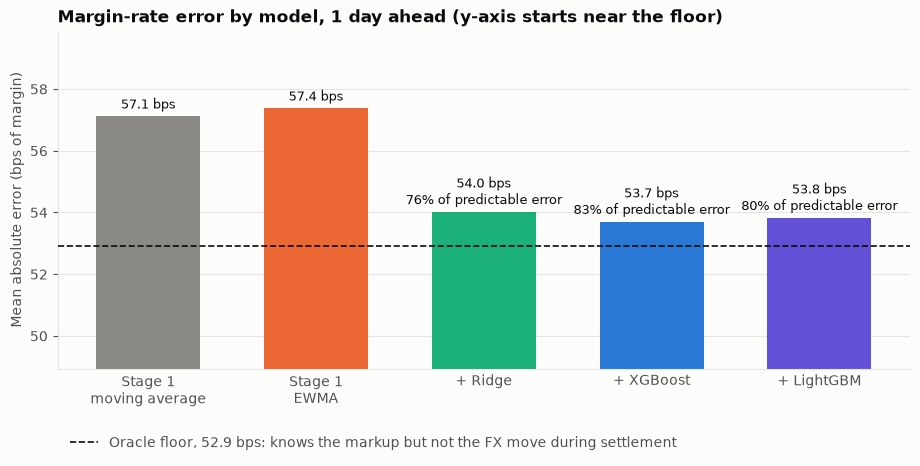

In [7]:
plots.plot_ladder(acc, 1, None)

## 5. Margin at risk
The 5% band should be breached on about 5% of days. Below, the most volatile stretch: real Brazilian real moves in October 2026, a 4.5% rally (margins below zero) and then an 8% sell-off (a windfall).

In [8]:
risk = risk_table(bt)
risk[risk.horizon == 1][['corridor', 'days', 'breach_rate', 'avg_shortfall_usd', 'avg_band_bps']].round(3)

,corridor,days,breach_rate,avg_shortfall_usd,avg_band_bps
0,BR,731,0.062,315132.427,133.466
1,IN,730,0.056,228316.860,69.865
2,MX,731,0.051,448066.811,117.683
6,All,2192,0.056,326182.297,107.021


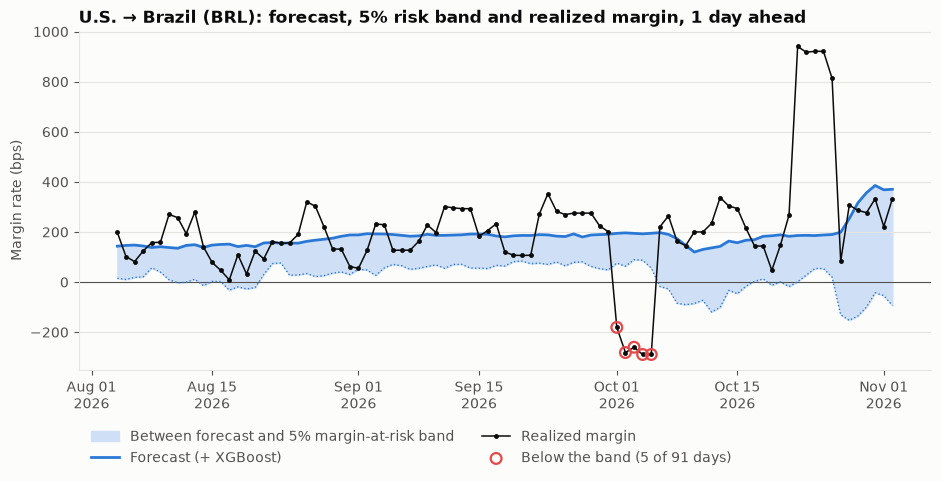

In [9]:
plots.plot_band(bt, 'BR', '2026-08-04', '2026-11-02', None)

## 6. What drives the correction
SHAP values for the XGBoost stage 2 model. The gap between today's markup and the stage 1 forecast dominates; volatility, FX momentum and the dollar index add smaller non-linear effects.

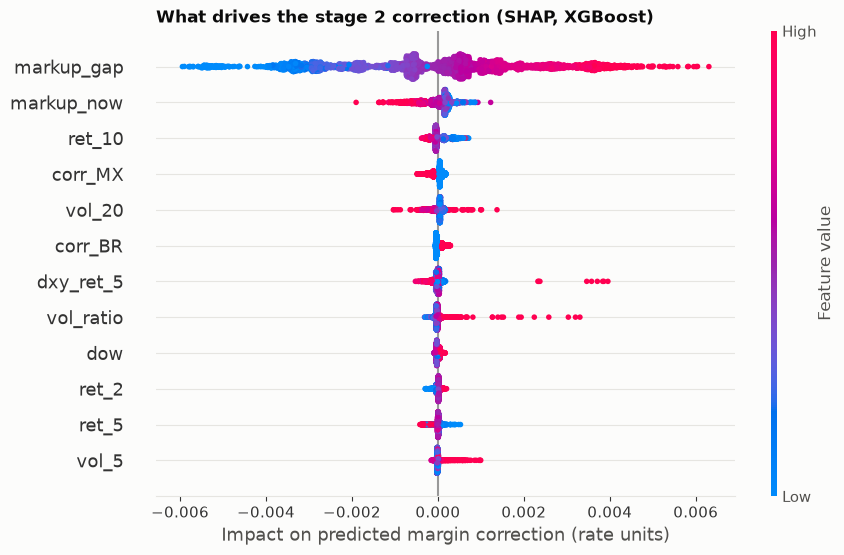

In [10]:
import shap
train = data[data.settle_date < data.origin.max()]
model = make_model('xgboost', load_params()).fit(train[FEATURES], train.resid)
sample = train[FEATURES].sample(3000, random_state=CONFIG.seed)
plots.plot_shap(shap.TreeExplainer(model).shap_values(sample), sample, None)